**G10 first**: AUD, CAD, CHF, EUR, GBP, JPY, NZD, NOK, SEK, USD

1. Load Data

In [1]:
!pip install fredapi
from fredapi import Fred
import pandas as pd
import numpy as np

fred = Fred(api_key="a9ebdc7fa5216c7293b22664624eaa95")

**Stage 1 - FX Data**

In [23]:
G10 = {
    "EUR": ("DEXUSEU", False),   # USD per EUR
    "GBP": ("DEXUSUK", False),   # USD per GBP
    "AUD": ("DEXUSAL", False),   # USD per AUD
    "NZD": ("DEXUSNZ", False),   # USD per NZD
    "JPY": ("DEXJPUS", True),    # JPY per USD
    "CAD": ("DEXCAUS", True),    # CAD per USD
    "CHF": ("DEXSZUS", True),    # CHF per USD
    "SEK": ("DEXSDUS", True),    # SEK per USD
    "NOK": ("DEXNOUS", True),    # NOK per USD
}

In [24]:
G10 = dict(sorted(G10.items()))
print(G10)

{'AUD': ('DEXUSAL', False), 'CAD': ('DEXCAUS', True), 'CHF': ('DEXSZUS', True), 'EUR': ('DEXUSEU', False), 'GBP': ('DEXUSUK', False), 'JPY': ('DEXJPUS', True), 'NOK': ('DEXNOUS', True), 'NZD': ('DEXUSNZ', False), 'SEK': ('DEXSDUS', True)}
{'AUD': ('DEXUSAL', False), 'CAD': ('DEXCAUS', True), 'CHF': ('DEXSZUS', True), 'EUR': ('DEXUSEU', False), 'GBP': ('DEXUSUK', False), 'JPY': ('DEXJPUS', True), 'NOK': ('DEXNOUS', True), 'NZD': ('DEXUSNZ', False), 'SEK': ('DEXSDUS', True)}


In [25]:
series = {}
for name, (ticker, invert) in G10.items():
    s = fred.get_series(ticker, observation_start="2000-01-01")
    series[name] = 1 / s if invert else s

USD per one foreign unit


,AUD,CAD,CHF,EUR,GBP,JPY,NOK,NZD,SEK
2026-08-27,0.7198,0.721813,1.244400,1.1654,1.3600,0.006279,0.10725,0.5953,0.105108
2026-08-28,0.7166,0.719683,1.236858,1.1598,1.3555,0.006251,0.10662,0.5915,0.104222


<Axes: title={'center': 'G10 (2000 – 2026)'}>

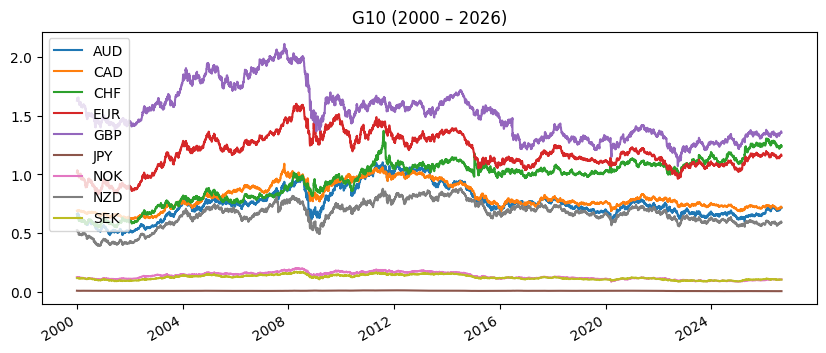

USD per one foreign unit


,AUD,CAD,CHF,EUR,GBP,JPY,NOK,NZD,SEK
2026-08-27,0.7198,0.721813,1.244400,1.1654,1.3600,0.006279,0.10725,0.5953,0.105108
2026-08-28,0.7166,0.719683,1.236858,1.1598,1.3555,0.006251,0.10662,0.5915,0.104222


<Axes: title={'center': 'G10 (2000 – 2026)'}>

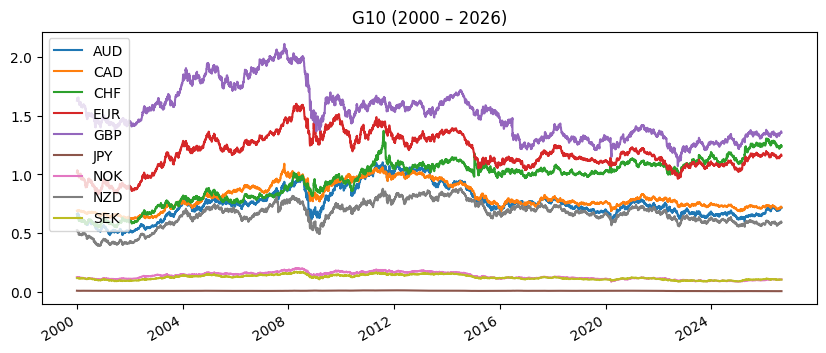

In [26]:
spot = pd.concat(series, axis=1).dropna()
print(f'USD per one foreign unit')
display(spot.tail(2))
display(spot.plot(figsize=(10,4), title='G10 (2000 – 2026)'))

**Stage 2 - Rates Data**

In [27]:
rates_data = pd.read_csv('/content/drive/MyDrive/TRADING 2027/G10Rates_Data.csv')
# Interest rate data of G10 countries: OECD, Short-term interest rates (3-month interbank rates, IR3TIB series), monthly, 2000–2026-05.

rates_cleaned = rates_data[["TIME_PERIOD", "Reference area", "OBS_VALUE"]]

rates = rates_cleaned.pivot(
    index="TIME_PERIOD",
    columns="Reference area",
    values="OBS_VALUE"
)
rates.index = pd.to_datetime(rates.index)
rates = rates.sort_index()


rates = rates.loc[rates.index >= '2000'] # Trimming as original starts from 1956
rates['United Kingdom'] = rates['United Kingdom'].ffill() # giving missing 4 most recent observation for UK (4 missing out of total 318), this has been forward-filled

display(rates.tail(3))

Reference area,Australia,Canada,Euro area (20 countries),Japan,New Zealand,Norway,Sweden,Switzerland,United Kingdom,United States
TIME_PERIOD,,,,,,,,,,
2026-04-01,4.34,2.2720,2.1753,1.24182,2.56,4.48,1.93585,-0.039834,3.62,3.77
2026-05-01,4.43,2.2925,2.2261,1.27409,2.63,4.56,1.95663,-0.039444,3.62,3.72
2026-06-01,4.46,2.2725,2.3390,NaN,2.68,4.57,1.95376,-0.045000,3.62,3.77


Reference area,Australia,Canada,Euro area (20 countries),Japan,New Zealand,Norway,Sweden,Switzerland,United Kingdom,United States
TIME_PERIOD,,,,,,,,,,
2026-04-01,4.34,2.2720,2.1753,1.24182,2.56,4.48,1.93585,-0.039834,3.62,3.77
2026-05-01,4.43,2.2925,2.2261,1.27409,2.63,4.56,1.95663,-0.039444,3.62,3.72
2026-06-01,4.46,2.2725,2.3390,NaN,2.68,4.57,1.95376,-0.045000,3.62,3.77


In [28]:
# Trimming data: Sample needs to be trimmed to 2026-05 as it's the last month with complete rate data across all G10 currencies
last_valid = rates.dropna().index.max()
print(f'The latest data will all available data for rates: {last_valid}.\n')
rates = rates.loc[:last_valid]
display(rates.tail(3))

The latest data will all available data for rates: 2026-05-01 00:00:00.



Reference area,Australia,Canada,Euro area (20 countries),Japan,New Zealand,Norway,Sweden,Switzerland,United Kingdom,United States
TIME_PERIOD,,,,,,,,,,
2026-03-01,4.19,2.2300,2.109409,1.26882,2.51,4.34,1.93618,-0.041196,3.62,3.69
2026-04-01,4.34,2.2720,2.175300,1.24182,2.56,4.48,1.93585,-0.039834,3.62,3.77
2026-05-01,4.43,2.2925,2.226100,1.27409,2.63,4.56,1.95663,-0.039444,3.62,3.72


The latest data will all available data for rates: 2026-05-01 00:00:00.



Reference area,Australia,Canada,Euro area (20 countries),Japan,New Zealand,Norway,Sweden,Switzerland,United Kingdom,United States
TIME_PERIOD,,,,,,,,,,
2026-03-01,4.19,2.2300,2.109409,1.26882,2.51,4.34,1.93618,-0.041196,3.62,3.69
2026-04-01,4.34,2.2720,2.175300,1.24182,2.56,4.48,1.93585,-0.039834,3.62,3.77
2026-05-01,4.43,2.2925,2.226100,1.27409,2.63,4.56,1.95663,-0.039444,3.62,3.72


In [29]:
rates = rates.rename(columns={
    "Australia": "AUD",
    "Canada": "CAD",
    "Japan": "JPY",
    "New Zealand": "NZD",
    "Norway": "NOK",
    "Sweden": "SEK",
    "Switzerland": "CHF",
    "United Kingdom": "GBP",
    "United States": "USD",
    "Euro area (20 countries)": "EUR"
})

rates = rates[sorted(rates.columns)]
display(rates)

Reference area,AUD,CAD,CHF,EUR,GBP,JPY,NOK,NZD,SEK,USD
TIME_PERIOD,,,,,,,,,,
2000-01-01,5.66,5.0250,1.729247,3.343143,6.13632,NaN,5.88,5.68,3.57000,5.95
2000-02-01,5.80,5.0325,2.237979,3.536762,6.23781,NaN,5.89,5.93,3.90000,6.01
2000-03-01,5.89,5.1080,2.430723,3.747044,6.22838,NaN,6.00,6.26,4.06000,6.14
2000-04-01,6.04,5.3500,2.812120,3.925278,6.29647,NaN,6.23,6.49,3.99000,6.28
2000-05-01,6.31,5.6640,3.010377,4.362045,6.30356,NaN,6.50,6.77,3.96000,6.71
...,...,...,...,...,...,...,...,...,...,...
2026-01-01,3.77,2.1900,-0.038886,2.027727,3.71000,1.11636,4.11,2.50,1.95770,3.63
2026-02-01,3.96,2.1775,-0.043500,2.011300,3.62000,1.22909,4.17,2.49,1.90740,3.66
2026-03-01,4.19,2.2300,-0.041196,2.109409,3.62000,1.26882,4.34,2.51,1.93618,3.69


Reference area,AUD,CAD,CHF,EUR,GBP,JPY,NOK,NZD,SEK,USD
TIME_PERIOD,,,,,,,,,,
2000-01-01,5.66,5.0250,1.729247,3.343143,6.13632,NaN,5.88,5.68,3.57000,5.95
2000-02-01,5.80,5.0325,2.237979,3.536762,6.23781,NaN,5.89,5.93,3.90000,6.01
2000-03-01,5.89,5.1080,2.430723,3.747044,6.22838,NaN,6.00,6.26,4.06000,6.14
2000-04-01,6.04,5.3500,2.812120,3.925278,6.29647,NaN,6.23,6.49,3.99000,6.28
2000-05-01,6.31,5.6640,3.010377,4.362045,6.30356,NaN,6.50,6.77,3.96000,6.71
...,...,...,...,...,...,...,...,...,...,...
2026-01-01,3.77,2.1900,-0.038886,2.027727,3.71000,1.11636,4.11,2.50,1.95770,3.63
2026-02-01,3.96,2.1775,-0.043500,2.011300,3.62000,1.22909,4.17,2.49,1.90740,3.66
2026-03-01,4.19,2.2300,-0.041196,2.109409,3.62000,1.26882,4.34,2.51,1.93618,3.69


**Matching the frequencies of Spot FX and Rates**

In [30]:
spot = spot.loc[:last_valid] # Accounting for the trimming in Rates dataset to the most recent period with all available data

rates_daily = rates.reindex(spot.index, method = 'ffill') # filling-in the rates' monthly observations to daily, such that spot can match rates frequencies
# reindex ties rates_daily's dates directly to spot's dates; resample would build its own calendar and need re-aligning after
display(rates_daily.tail(3))

Reference area,AUD,CAD,CHF,EUR,GBP,JPY,NOK,NZD,SEK,USD
2026-04-29,4.34,2.2720,-0.039834,2.1753,3.62,1.24182,4.48,2.56,1.93585,3.77
2026-04-30,4.34,2.2720,-0.039834,2.1753,3.62,1.24182,4.48,2.56,1.93585,3.77
2026-05-01,4.43,2.2925,-0.039444,2.2261,3.62,1.27409,4.56,2.63,1.95663,3.72


Reference area,AUD,CAD,CHF,EUR,GBP,JPY,NOK,NZD,SEK,USD
2026-04-29,4.34,2.2720,-0.039834,2.1753,3.62,1.24182,4.48,2.56,1.93585,3.77
2026-04-30,4.34,2.2720,-0.039834,2.1753,3.62,1.24182,4.48,2.56,1.93585,3.77
2026-05-01,4.43,2.2925,-0.039444,2.2261,3.62,1.27409,4.56,2.63,1.95663,3.72


***Stage 3 – Raw Carry***

In [31]:
carry = rates_daily.sub(rates_daily["USD"], axis=0)
# plain '-' aligns Series-vs-DataFrame by columns (axis=1) by default --> error;
# axis=0 forces row-wise alignment by date instead, which can be done by using .sub() function

display(carry.tail())
carry = carry.drop(columns='USD')
# Carry was computed as a rate-differential proxy against USD (rate_i − rate_USD), not from actual forward points.
# Theory says they're equivalent under CIP, but in reality they don't hold post-GFC.
# Thefore, it's a simplification versus real market forward pricing due to limited data.

Reference area,AUD,CAD,CHF,EUR,GBP,JPY,NOK,NZD,SEK,USD
2026-04-27,0.57,-1.4980,-3.809833,-1.5947,-0.15,-2.52818,0.71,-1.21,-1.83415,0.0
2026-04-28,0.57,-1.4980,-3.809833,-1.5947,-0.15,-2.52818,0.71,-1.21,-1.83415,0.0
2026-04-29,0.57,-1.4980,-3.809833,-1.5947,-0.15,-2.52818,0.71,-1.21,-1.83415,0.0
2026-04-30,0.57,-1.4980,-3.809833,-1.5947,-0.15,-2.52818,0.71,-1.21,-1.83415,0.0
2026-05-01,0.71,-1.4275,-3.759444,-1.4939,-0.10,-2.44591,0.84,-1.09,-1.76337,0.0


Reference area,AUD,CAD,CHF,EUR,GBP,JPY,NOK,NZD,SEK,USD
2026-04-27,0.57,-1.4980,-3.809833,-1.5947,-0.15,-2.52818,0.71,-1.21,-1.83415,0.0
2026-04-28,0.57,-1.4980,-3.809833,-1.5947,-0.15,-2.52818,0.71,-1.21,-1.83415,0.0
2026-04-29,0.57,-1.4980,-3.809833,-1.5947,-0.15,-2.52818,0.71,-1.21,-1.83415,0.0
2026-04-30,0.57,-1.4980,-3.809833,-1.5947,-0.15,-2.52818,0.71,-1.21,-1.83415,0.0
2026-05-01,0.71,-1.4275,-3.759444,-1.4939,-0.10,-2.44591,0.84,-1.09,-1.76337,0.0


**Stage 4 – Volatility**

In [32]:
spot_pct = spot.pct_change()
vol = rolling_std = np.sqrt(252) * spot_pct.rolling(window=252).std() # annualized (sqrt responsible) and rolling (spot_pct.rolling(...)) volatility
display(vol.round(2).tail())

,AUD,CAD,CHF,EUR,GBP,JPY,NOK,NZD,SEK
2026-04-27,0.08,0.05,0.08,0.06,0.06,0.09,0.09,0.09,0.1
2026-04-28,0.08,0.05,0.08,0.06,0.06,0.09,0.09,0.09,0.1
2026-04-29,0.08,0.05,0.08,0.06,0.06,0.09,0.09,0.09,0.1
2026-04-30,0.08,0.05,0.08,0.06,0.06,0.09,0.09,0.09,0.1
2026-05-01,0.08,0.05,0.08,0.06,0.06,0.09,0.09,0.09,0.1


,AUD,CAD,CHF,EUR,GBP,JPY,NOK,NZD,SEK
2026-04-27,0.08,0.05,0.08,0.06,0.06,0.09,0.09,0.09,0.1
2026-04-28,0.08,0.05,0.08,0.06,0.06,0.09,0.09,0.09,0.1
2026-04-29,0.08,0.05,0.08,0.06,0.06,0.09,0.09,0.09,0.1
2026-04-30,0.08,0.05,0.08,0.06,0.06,0.09,0.09,0.09,0.1
2026-05-01,0.08,0.05,0.08,0.06,0.06,0.09,0.09,0.09,0.1


**Stage 5 – Score and Rank**

In [33]:
exp_sharpe = ((carry/100) / vol)
print(f'\nExpected Sharpe:')
display(exp_sharpe.round(2).tail())


Expected Sharpe:


Reference area,AUD,CAD,CHF,EUR,GBP,JPY,NOK,NZD,SEK
2026-04-27,0.07,-0.32,-0.50,-0.25,-0.02,-0.28,0.08,-0.14,-0.19
2026-04-28,0.07,-0.32,-0.50,-0.25,-0.02,-0.28,0.08,-0.14,-0.19
2026-04-29,0.07,-0.32,-0.50,-0.25,-0.02,-0.28,0.08,-0.14,-0.19
2026-04-30,0.07,-0.32,-0.50,-0.25,-0.02,-0.27,0.08,-0.14,-0.19
2026-05-01,0.09,-0.30,-0.49,-0.23,-0.02,-0.26,0.10,-0.12,-0.18



Expected Sharpe:


Reference area,AUD,CAD,CHF,EUR,GBP,JPY,NOK,NZD,SEK
2026-04-27,0.07,-0.32,-0.50,-0.25,-0.02,-0.28,0.08,-0.14,-0.19
2026-04-28,0.07,-0.32,-0.50,-0.25,-0.02,-0.28,0.08,-0.14,-0.19
2026-04-29,0.07,-0.32,-0.50,-0.25,-0.02,-0.28,0.08,-0.14,-0.19
2026-04-30,0.07,-0.32,-0.50,-0.25,-0.02,-0.27,0.08,-0.14,-0.19
2026-05-01,0.09,-0.30,-0.49,-0.23,-0.02,-0.26,0.10,-0.12,-0.18


In [34]:
print(f'Ranking:')
ranking_exp_sharpe = exp_sharpe.iloc[-1].sort_values(ascending = False)
display(ranking_exp_sharpe.round(2))

print(f'\nGeneral Monitor:')

monitor = pd.concat([carry.iloc[-1], vol.iloc[-1], exp_sharpe.iloc[-1]], axis=1)
monitor.columns = ['Carry', 'Volatility', 'Exp_Sharpe']
display(monitor.sort_values(by='Exp_Sharpe', ascending = False ))

Ranking:


,2026-05-01
Reference area,
NOK,0.10
AUD,0.09
GBP,-0.02
NZD,-0.12
SEK,-0.18
EUR,-0.23
JPY,-0.26
CAD,-0.30
CHF,-0.49



General Monitor:


,Carry,Volatility,Exp_Sharpe
NOK,0.840000,0.088159,0.095283
AUD,0.710000,0.081744,0.086856
GBP,-0.100000,0.064340,-0.015542
NZD,-1.090000,0.087258,-0.124917
SEK,-1.763370,0.095811,-0.184046
EUR,-1.493900,0.063911,-0.233746
JPY,-2.445910,0.093322,-0.262095
CAD,-1.427500,0.047577,-0.300043
CHF,-3.759444,0.076782,-0.489626


Ranking:


,2026-05-01
Reference area,
NOK,0.10
AUD,0.09
GBP,-0.02
NZD,-0.12
SEK,-0.18
EUR,-0.23
JPY,-0.26
CAD,-0.30
CHF,-0.49



General Monitor:


,Carry,Volatility,Exp_Sharpe
NOK,0.840000,0.088159,0.095283
AUD,0.710000,0.081744,0.086856
GBP,-0.100000,0.064340,-0.015542
NZD,-1.090000,0.087258,-0.124917
SEK,-1.763370,0.095811,-0.184046
EUR,-1.493900,0.063911,-0.233746
JPY,-2.445910,0.093322,-0.262095
CAD,-1.427500,0.047577,-0.300043
CHF,-3.759444,0.076782,-0.489626


**Stage 6 – Forming the actual Portfolio**

In [35]:
# Rebalancing monthly to avoid transaction costs. At each rebalance date, go long the top three by expected Sharpe and short the bottom three.
signal_monthly = exp_sharpe.resample("ME").last()
display(signal_monthly.tail(3))

ranks_desc = signal_monthly.rank(axis=1, ascending=False)
ranks_asc  = signal_monthly.rank(axis=1, ascending=True)
# done separetely to not hardcode the last three currencies
# So having to manually find that the last three would start with rank 7. That makes the code fragile if given different # of currencies.

longs  = (ranks_desc <= 3)
shorts = (ranks_asc  <= 3)
weights_equal = longs / 3 - shorts / 3

print(f'\nPortfolio allocation by month based on equal-weights (for Rebalancing information purposes):')
display(weights_equal.tail(2))


# with equal notional weights, the P&L gets dominated by whichever currency happens to be most volatile.
# Solution: Inverse-vol weight – size each position proportional to 1/σ, so each contributes roughly equal risk rather than equal notional.
# Relatively simple but at the expense that it ignores asset correlations
print(f'\n')
vol_monthly = vol.resample("ME").last()
vol_monthly_reciprocal = 1 / vol_monthly

longs_masking = vol_monthly_reciprocal * longs
longs_allocation = longs_masking.div(longs_masking.sum(axis = 1), axis=0)

shorts_masking = vol_monthly_reciprocal * shorts
shorts_allocation = - shorts_masking.div(shorts_masking.sum(axis = 1), axis=0)

# sum(axis=1) gives one total per date (a Series indexed by date); plain '/' would try to match those dates
# against column names and return NaN, so .div(axis=0) is needed to align row-wise instead # STUDY THIS AGAIN

weights_inverse_vol = longs_allocation + shorts_allocation
print(f'Portfolio allocation by month based on Inverse-Vol weight:')
display(weights_inverse_vol.tail(3))

print(f'\nVerifying if sum of portfolio allocation from both longs and shorts equals 0:\n{weights_inverse_vol.iloc[-1].sum(axis=0).round(2)}')

Reference area,AUD,CAD,CHF,EUR,GBP,JPY,NOK,NZD,SEK
2026-03-31,0.050019,-0.271605,-0.428800,-0.223276,-0.010181,-0.247037,0.063155,-0.118503,-0.172881
2026-04-30,0.069708,-0.315321,-0.496590,-0.249638,-0.023338,-0.270748,0.080607,-0.138689,-0.191831
2026-05-31,0.086856,-0.300043,-0.489626,-0.233746,-0.015542,-0.262095,0.095283,-0.124917,-0.184046



Portfolio allocation by month based on equal-weights (for Rebalancing information purposes):


Reference area,AUD,CAD,CHF,EUR,GBP,JPY,NOK,NZD,SEK
2026-04-30,0.333333,-0.333333,-0.333333,0.0,0.333333,-0.333333,0.333333,0.0,0.0
2026-05-31,0.333333,-0.333333,-0.333333,0.0,0.333333,-0.333333,0.333333,0.0,0.0




Portfolio allocation by month based on Inverse-Vol weight:


,AUD,CAD,CHF,EUR,GBP,JPY,NOK,NZD,SEK
2026-03-31,0.291956,-0.461632,-0.285179,0.0,0.424480,-0.253189,0.283564,0.0,0.0
2026-04-30,0.312442,-0.469927,-0.290992,0.0,0.397505,-0.239082,0.290053,0.0,0.0
2026-05-31,0.312721,-0.469606,-0.290983,0.0,0.397313,-0.239411,0.289966,0.0,0.0


...


Portfolio allocation by month based on equal-weights (for Rebalancing information purposes):


Reference area,AUD,CAD,CHF,EUR,GBP,JPY,NOK,NZD,SEK
2026-04-30,0.333333,-0.333333,-0.333333,0.0,0.333333,-0.333333,0.333333,0.0,0.0
2026-05-31,0.333333,-0.333333,-0.333333,0.0,0.333333,-0.333333,0.333333,0.0,0.0




Portfolio allocation by month based on Inverse-Vol weight:


,AUD,CAD,CHF,EUR,GBP,JPY,NOK,NZD,SEK
2026-03-31,0.291956,-0.461632,-0.285179,0.0,0.424480,-0.253189,0.283564,0.0,0.0
2026-04-30,0.312442,-0.469927,-0.290992,0.0,0.397505,-0.239082,0.290053,0.0,0.0
2026-05-31,0.312721,-0.469606,-0.290983,0.0,0.397313,-0.239411,0.289966,0.0,0.0



Verifying if sum of portfolio allocation from both longs and shorts equals 0:
0.0


**Stage 7 – The lag.**
It is used to prevent look-ahead bias.

In [36]:
lagged_weights_equal = weights_equal.shift(1)
lagged_weights_inverse_vol = weights_inverse_vol.shift(1)

**Stage 8 – Monthly returns**

In [37]:
monthly_r = carry.resample('ME').last()/100/12 + spot.resample('ME').last().pct_change()
# total return you'd earn from holding one unit of that currency against USD for that month, expressed as a decimal
# ^ to match spot_pct: carry is in pct points (so /100) and is annualized (so needs /12).

display(monthly_r.tail(3))
print('\n')

monthly_r = monthly_r.iloc[:-1] # given last observation (May) comes from a single day value, it distorts the reality. Thus, it is dropped.
display(monthly_r.tail(3))

Reference area,AUD,CAD,CHF,EUR,GBP,JPY,NOK,NZD,SEK
2026-03-31,-0.036938,-0.024222,-0.045591,-0.027032,-0.020200,-0.021065,-0.023665,-0.049317,-0.055285
2026-04-30,0.048469,0.023878,0.022771,0.016990,0.029911,0.013341,0.049409,0.030866,0.029111
2026-05-31,0.005464,0.001462,0.000459,0.000972,0.002936,-0.002676,0.004861,0.003504,0.004873


Reference area,AUD,CAD,CHF,EUR,GBP,JPY,NOK,NZD,SEK
2026-02-28,0.018263,-0.006737,0.000036,-0.006675,-0.019991,-0.012984,0.008911,-0.008912,-0.018567
2026-03-31,-0.036938,-0.024222,-0.045591,-0.027032,-0.020200,-0.021065,-0.023665,-0.049317,-0.055285
2026-04-30,0.048469,0.023878,0.022771,0.016990,0.029911,0.013341,0.049409,0.030866,0.029111


Reference area,AUD,CAD,CHF,EUR,GBP,JPY,NOK,NZD,SEK
2026-03-31,-0.036938,-0.024222,-0.045591,-0.027032,-0.020200,-0.021065,-0.023665,-0.049317,-0.055285
2026-04-30,0.048469,0.023878,0.022771,0.016990,0.029911,0.013341,0.049409,0.030866,0.029111
2026-05-31,0.005464,0.001462,0.000459,0.000972,0.002936,-0.002676,0.004861,0.003504,0.004873


Reference area,AUD,CAD,CHF,EUR,GBP,JPY,NOK,NZD,SEK
2026-02-28,0.018263,-0.006737,0.000036,-0.006675,-0.019991,-0.012984,0.008911,-0.008912,-0.018567
2026-03-31,-0.036938,-0.024222,-0.045591,-0.027032,-0.020200,-0.021065,-0.023665,-0.049317,-0.055285
2026-04-30,0.048469,0.023878,0.022771,0.016990,0.029911,0.013341,0.049409,0.030866,0.029111


**Stage 9 – Transaction Costs & Portfolio Returns**

In [38]:
# TRANSACTION COSTS – assumption of 3bps per unit of turnover.
# take the absolute difference of your lagged weights row-to-row, sum across currencies to get total turnover per month,
# then multiply by a cost in basis points. Subtract that from your portfolio return.

turnover_equal = lagged_weights_equal.diff().abs().sum(axis = 1) # STUDY AGAIN
turnover_equal_cost = turnover_equal * 0.0003 # based on 3bps assumpion

turnover_ivvol = lagged_weights_inverse_vol.diff().abs().sum(axis = 1)
turnover_ivvol_cost = turnover_ivvol * 0.0003 # based on 3bps assumption

In [39]:
portfolio_r_equal = (monthly_r * lagged_weights_equal).sum(axis = 1) - turnover_equal_cost
portfolio_r_ivvol = (monthly_r * lagged_weights_inverse_vol).sum(axis = 1) - turnover_ivvol_cost
display(portfolio_r_ivvol)
portfolio_r_equal = portfolio_r_equal.loc['2002-05-31':][:-1]
portfolio_r_ivvol = portfolio_r_ivvol.loc['2002-05-31':][:-1]

# Trim needed at both ends before computing metrics:
# FRONT — JPY's OECD rate series starts 2002-04-01, so the first month-end where all
#         nine currencies are rankable is 2002-04-30. With shift(1), that gives a first
#         clean return of 2002-05-31. Vol (first valid 2001-01-02) and pct_change are
#         not binding.
# BACK  — weight tables run one month past monthly_r, so the final row is meaningless:
#         zero return minus a residual turnover cost.

print(f'Portfolio Returns equal-weighted:')
display(portfolio_r_equal)
print(f'\nPortfolio Returns inverse volatility-weighted:')
display(portfolio_r_ivvol)

,0
2000-01-31,0.000000
2000-02-29,0.000000
2000-03-31,0.000000
2000-04-30,0.000000
2000-05-31,0.000000
...,...
2026-01-31,0.022170
2026-02-28,0.005652
2026-03-31,0.003584
2026-04-30,0.019958


Portfolio Returns equal-weighted:


,0
2002-05-31,0.013718
2002-06-30,0.012864
2002-07-31,0.007440
2002-08-31,0.004191
2002-09-30,0.015537
...,...
2025-12-31,0.005404
2026-01-31,0.023782
2026-02-28,0.008956
2026-03-31,0.003359



Portfolio Returns inverse volatility-weighted:


,0
2002-05-31,0.009796
2002-06-30,0.020233
2002-07-31,0.018730
2002-08-31,0.002884
2002-09-30,0.016101
...,...
2025-12-31,0.003687
2026-01-31,0.022170
2026-02-28,0.005652
2026-03-31,0.003584


,0
2000-01-31,0.000000
2000-02-29,0.000000
2000-03-31,0.000000
2000-04-30,0.000000
2000-05-31,0.000000
...,...
2026-01-31,0.022170
2026-02-28,0.005652
2026-03-31,0.003584
2026-04-30,0.019958


Portfolio Returns equal-weighted:


,0
2002-05-31,0.013718
2002-06-30,0.012864
2002-07-31,0.007440
2002-08-31,0.004191
2002-09-30,0.015537
...,...
2025-12-31,0.005404
2026-01-31,0.023782
2026-02-28,0.008956
2026-03-31,0.003359



Portfolio Returns inverse volatility-weighted:


,0
2002-05-31,0.009796
2002-06-30,0.020233
2002-07-31,0.018730
2002-08-31,0.002884
2002-09-30,0.016101
...,...
2025-12-31,0.003687
2026-01-31,0.022170
2026-02-28,0.005652
2026-03-31,0.003584


**Stage 10 – Metrics**

In [40]:
# Sharpe
sharpe_equal = (portfolio_r_equal.mean()*12) / (portfolio_r_equal.std() * np.sqrt(12))
sharpe_ivvol = (portfolio_r_ivvol.mean()*12) / (portfolio_r_ivvol.std() * np.sqrt(12))

# Max drawdown
cum_returns_equal = (1 + portfolio_r_equal).cumprod()
drawdown_equal = (cum_returns_equal / cum_returns_equal.cummax()) - 1 # STUDY THIS AGAIN
min_drawdown_equal = drawdown_equal.min()

cum_returns_ivvol = (1 + portfolio_r_ivvol).cumprod()
drawdown_ivvol = (cum_returns_ivvol / cum_returns_ivvol.cummax()) - 1
min_drawdown_ivvol = drawdown_ivvol.min()

# hit rate
hit_rate_equal = (portfolio_r_equal > 0).sum() / portfolio_r_equal.count()
hit_rate_ivvol = (portfolio_r_ivvol > 0).sum() / portfolio_r_ivvol.count()

# Skew – measures the asymmetry of the return distribution.
skew_equal = portfolio_r_equal.skew()
skew_ivvol = portfolio_r_ivvol.skew()

# Average Annual Turnover
annualized_turnover_equal = turnover_equal.loc[portfolio_r_equal.index].mean() * 12
annualized_turnover_ivvol = turnover_ivvol.loc[portfolio_r_ivvol.index].mean() * 12

# Results
print(f'Equal-weighted results')
print(f"Sharpe ratio: {sharpe_equal.round(2)}")
print(f"Minimum drawdown took place on {drawdown_equal.idxmin().date()}, noting {min_drawdown_equal:.1%}.")
print(f"Hit Rate: {hit_rate_equal.round(2)}")
print(f"Skew: {skew_equal.round(2)}")
print(f"Annualized Turnover: {annualized_turnover_equal.round(2)}\n")

print(f'Inverse vol-weighted results')
print(f"Sharpe ratio: {sharpe_ivvol.round(2)}")
print(f'Minimum drawdown took place on {drawdown_ivvol.idxmin().date()}, noting {min_drawdown_ivvol:.1%}.')
print(f"Hit Rate: {hit_rate_ivvol.round(2)}")
print(f'Skew: {skew_ivvol.round(2)}')
print(f"Annualized Turnover: {annualized_turnover_ivvol.round(2)}")

Equal-weighted results
Sharpe ratio: 0.41
Minimum drawdown took place on 2009-01-31, noting -26.0%.
Hit Rate: 0.59
Skew: -0.52
Annualized Turnover: 1.58

Inverse vol-weighted results
Sharpe ratio: 0.38
Minimum drawdown took place on 2009-01-31, noting -26.3%.
Hit Rate: 0.59
Skew: -0.45
Annualized Turnover: 1.96
Equal-weighted results
Sharpe ratio: 0.41
Minimum drawdown took place on 2009-01-31, noting -26.0%.
Hit Rate: 0.59
Skew: -0.52
Annualized Turnover: 1.58

Inverse vol-weighted results
Sharpe ratio: 0.38
Minimum drawdown took place on 2009-01-31, noting -26.3%.
Hit Rate: 0.59
Skew: -0.45
Annualized Turnover: 1.96


**Headline results (2002-05 to 2026-04)**

* Sharpe ≈ 0.41 equal-weight, 0.38 inverse-vol — bottom of the 0.4–0.7 range
* typically reported for G10 carry
* Low end is the expected outcome, not a disappointing one: the sample includes the post-2008 ZIRP decade when G10 differentials compressed to almost nothing, and returns are charged 3bp per unit of turnover
* Max drawdown ≈ −26%, peaking January 2009
* Hit rate 0.59, skew −0.52

**Negative skew is the central finding**

* Carry behaves like selling insurance: premium collected in small regular increments, paid back in rare violent unwinds
* Hit rate of 0.59 confirms the same profile independently — wins most months, loses more when it loses
Sharpe measures risk as standard deviation, which squares deviations and so treats a large gain as exactly as much risk as a large loss
* That makes it blind to skew: two strategies with the same mean and vol score identically whether their tail is on the upside or the downside
* Hence skew and drawdown are reported alongside — they show that this strategy's risk arrives concentrated in short episodes, which Sharpe cannot express

**Equal-weight vs inverse-volatility**

* Inverse-vol does worse on Sharpe (0.38 vs 0.41) and slightly worse on drawdown, better on skew (−0.45 vs −0.52), and trades 24% more (1.96 vs 1.58 turns per year)
* The extra trading isn't the reason. The difference in turnover costs about 1bp a year at 3bp, far too small to explain the gap in returns
* The weighting is the reason. In G10, the high-yielding currencies are also the volatile ones — they pay a premium because they're the ones that sell off when markets turn. Dividing by vol therefore cuts the biggest carry positions and boosts the smallest, so return falls at least as much as risk does
* The signal makes this worse. It's already carry / vol, so vol picks the currencies and then sizes them as well. The volatile names get marked down twice for the same reason
* Inverse-vol works when the signal ignores vol. This one doesn't
The better skew is real, so it's a trade-off, not a failure — a bit less return per unit of risk, in exchange for a smaller left tail

**Methodological notes**

* Portfolio is zero-net-investment, so returns are already excess — no risk-free rate subtracted
* Annualisation: mean × 12, volatility × √12; assumes serially independent monthly returns
* All metrics computed over the identical trimmed window, turnover included

Equity Curves of the strategy:


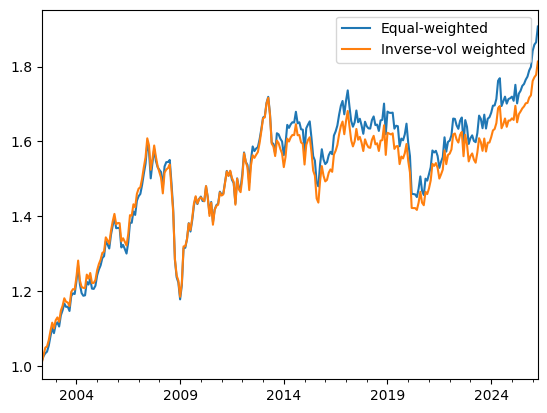

Equity Curves of the strategy:


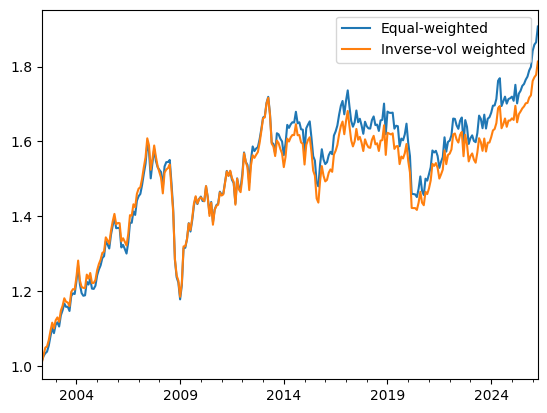

In [41]:
print(f'Equity Curves of the strategy:')

ax = (1 + portfolio_r_equal).cumprod().plot(label="Equal-weighted")
(1 + portfolio_r_ivvol).cumprod().plot(ax=ax, label="Inverse-vol weighted")
ax.legend()

**What the equity curve shows**

* Steady compounding 2002–2007
* Sharp crisis drawdown into early 2009
* Flat through the ZIRP decade — little carry available to harvest
* Recovery from ~2021 as the Fed hiked ahead of the ECB and BoJ

**Stage 11 – Robustness**

252-day vol window and monthly rebalancing

The structure. Three parts.

Refactor Stages 4–10 into a function. Right now the pipeline is spread across cells with hardcoded 252 and monthly resampling. You need one function that takes vol_window and rebalance_freq as arguments and returns the metrics. Everything from vol through to Sharpe goes inside it. This is the real work of the stage, and it's mostly moving code you already have.

Loop over the combinations. Vol windows of 60, 90, 252; rebalance frequencies of monthly and quarterly. That's six cells. Nested loops, appending each result to a list.

Tabulate. Collect the results into a DataFrame with vol windows as rows and frequencies as columns, values being Sharpe. Six numbers you can read at a glance.

In [42]:
# vol = rolling_std = np.sqrt(252) * spot_pct.rolling(window=252).std() # annualized (sqrt responsible) and rolling (spot_pct.rolling(...)) volatility
# the vol-measure window and resampling needs to be taken as a function as those are big assumptions in the analysis.

# how can I replicate vol-measure window and resampling without hardcoding the whole data and copy-pasting code with different assumptions.
# replicating Stages 4-10 to robust check the two assumptions: vol-measure window and resampling

def run_backtest(vol_window, rebalance_freq, cost_bps = 0.0003):

    periods_per_year = {'ME': 12, 'QE': 4}[rebalance_freq]

    # vol from spot using vol_window
    spot_pct = spot.pct_change()
    vol = np.sqrt(vol_window) * spot_pct.rolling(window = vol_window).std()

    # exp_sharpe
    exp_sharpe = ((carry/100) / vol)

    # resample to rebalance_freq, rank, build both weight tables, shift(1)
    signal = exp_sharpe.resample(rebalance_freq).last()

    ranks_desc = signal.rank(axis=1, ascending=False)
    ranks_asc  = signal.rank(axis=1, ascending=True)

    longs  = (ranks_desc <= 3)
    shorts = (ranks_asc  <= 3)
    weights_equal = longs / 3 - shorts / 3

    vol_resampled = vol.resample(rebalance_freq).last()
    vol_reciprocal = 1 / vol_resampled

    longs_masking = vol_reciprocal * longs
    longs_allocation = longs_masking.div(longs_masking.sum(axis = 1), axis=0)

    shorts_masking = vol_reciprocal * shorts
    shorts_allocation = - shorts_masking.div(shorts_masking.sum(axis = 1), axis=0)

    weights_inverse_vol = longs_allocation + shorts_allocation

    lagged_weights_equal = weights_equal.shift(1)
    lagged_weights_inverse_vol = weights_inverse_vol.shift(1)

    # returns, turnover, costs
    period_r = carry.resample(rebalance_freq).last()/100/periods_per_year + spot.resample(rebalance_freq).last().pct_change()
    period_r = period_r.iloc[:-1] # given last observation (May) comes from a single day value, it distorts the reality. Thus, it is dropped.

    turnover_equal = lagged_weights_equal.diff().abs().sum(axis = 1)
    turnover_equal_cost = turnover_equal * cost_bps
    turnover_ivvol = lagged_weights_inverse_vol.diff().abs().sum(axis = 1)
    turnover_ivvol_cost = turnover_ivvol * cost_bps

    portfolio_r_equal = (period_r * lagged_weights_equal).sum(axis = 1) - turnover_equal_cost
    portfolio_r_ivvol = (period_r * lagged_weights_inverse_vol).sum(axis = 1) - turnover_ivvol_cost

    START = {'ME': '2002-05-31', 'QE': '2002-09-30'}[rebalance_freq]
    portfolio_r_equal = portfolio_r_equal.loc[START:][:-1]
    portfolio_r_ivvol = portfolio_r_ivvol.loc[START:][:-1]

    # trim to common window
    sharpe_equal = (portfolio_r_equal.mean() * periods_per_year) / (portfolio_r_equal.std() * np.sqrt(periods_per_year))
    sharpe_ivvol = (portfolio_r_ivvol.mean() * periods_per_year) / (portfolio_r_ivvol.std() * np.sqrt(periods_per_year))

    cum_returns_equal = (1 + portfolio_r_equal).cumprod()
    drawdown_equal = (cum_returns_equal / cum_returns_equal.cummax()) - 1 # STUDY THIS AGAIN
    min_drawdown_equal = drawdown_equal.min()

    cum_returns_ivvol = (1 + portfolio_r_ivvol).cumprod()
    drawdown_ivvol = (cum_returns_ivvol / cum_returns_ivvol.cummax()) - 1
    min_drawdown_ivvol = drawdown_ivvol.min()

    hit_rate_equal = (portfolio_r_equal > 0).sum() / portfolio_r_equal.count()
    hit_rate_ivvol = (portfolio_r_ivvol > 0).sum() / portfolio_r_ivvol.count()

    skew_equal = portfolio_r_equal.skew()
    skew_ivvol = portfolio_r_ivvol.skew()

    annualized_turnover_equal = turnover_equal.loc[portfolio_r_equal.index].mean() * periods_per_year
    annualized_turnover_ivvol = turnover_ivvol.loc[portfolio_r_ivvol.index].mean() * periods_per_year

    # Return a dict of the five metrics for both schemes
    return {
        'vol_window': vol_window,
        'freq': rebalance_freq,
        'sharpe_eq': sharpe_equal,
        'sharpe_iv': sharpe_ivvol,
        'maxdd_eq': min_drawdown_equal,
        'maxdd_iv': min_drawdown_ivvol,
        'hit_eq': hit_rate_equal,
        'hit_iv': hit_rate_ivvol,
        'skew_eq': skew_equal,
        'skew_iv': skew_ivvol,
        'turn_eq': annualized_turnover_equal,
        'turn_iv': annualized_turnover_ivvol,
    }

run_backtest(252,'ME')

{'vol_window': 252,
 'freq': 'ME',
 'sharpe_eq': np.float64(0.40804891226627343),
 'sharpe_iv': np.float64(0.38420050061079775),
 'maxdd_eq': -0.2603739956490224,
 'maxdd_iv': -0.2631277084023307,
 'hit_eq': np.float64(0.5868055555555556),
 'hit_iv': np.float64(0.5868055555555556),
 'skew_eq': np.float64(-0.5217116186337377),
 'skew_iv': np.float64(-0.45011147726228273),
 'turn_eq': np.float64(1.5833333333333335),
 'turn_iv': np.float64(1.9581374677991525)}

{'vol_window': 252,
 'freq': 'ME',
 'sharpe_eq': np.float64(0.40804891226627343),
 'sharpe_iv': np.float64(0.38420050061079775),
 'maxdd_eq': -0.2603739956490224,
 'maxdd_iv': -0.2631277084023307,
 'hit_eq': np.float64(0.5868055555555556),
 'hit_iv': np.float64(0.5868055555555556),
 'skew_eq': np.float64(-0.5217116186337377),
 'skew_iv': np.float64(-0.45011147726228273),
 'turn_eq': np.float64(1.5833333333333335),
 'turn_iv': np.float64(1.9581374677991525)}

In [43]:
results = []
for w in [60, 90, 252]:
    for f in ['ME', 'QE']:
        results.append(run_backtest(w, f))

grid = pd.DataFrame(results)

display(grid.round(3))

,vol_window,freq,sharpe_eq,sharpe_iv,maxdd_eq,maxdd_iv,hit_eq,hit_iv,skew_eq,skew_iv,turn_eq,turn_iv
0,60,ME,0.366,0.332,-0.280,-0.295,0.587,0.587,-0.563,-0.485,2.056,3.300
1,60,QE,0.342,0.315,-0.285,-0.296,0.642,0.621,-1.355,-1.310,1.375,2.238
2,90,ME,0.379,0.337,-0.274,-0.291,0.587,0.573,-0.583,-0.504,1.694,2.552
3,90,QE,0.387,0.360,-0.251,-0.262,0.642,0.611,-1.317,-1.140,1.235,1.890
4,252,ME,0.408,0.384,-0.260,-0.263,0.587,0.587,-0.522,-0.450,1.583,1.958
5,252,QE,0.349,0.318,-0.259,-0.270,0.642,0.621,-1.491,-1.474,1.095,1.474


,vol_window,freq,sharpe_eq,sharpe_iv,maxdd_eq,maxdd_iv,hit_eq,hit_iv,skew_eq,skew_iv,turn_eq,turn_iv
0,60,ME,0.366,0.332,-0.280,-0.295,0.587,0.587,-0.563,-0.485,2.056,3.300
1,60,QE,0.342,0.315,-0.285,-0.296,0.642,0.621,-1.355,-1.310,1.375,2.238
2,90,ME,0.379,0.337,-0.274,-0.291,0.587,0.573,-0.583,-0.504,1.694,2.552
3,90,QE,0.387,0.360,-0.251,-0.262,0.642,0.611,-1.317,-1.140,1.235,1.890
4,252,ME,0.408,0.384,-0.260,-0.263,0.587,0.587,-0.522,-0.450,1.583,1.958
5,252,QE,0.349,0.318,-0.259,-0.270,0.642,0.621,-1.491,-1.474,1.095,1.474
